# DenseSAGEConv on fully connected, undirected, graph with the fixes to accuracy computation backported from the directed version

# Dependencies (for venv)

In [1]:
pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


# Generate the dataset

In [2]:
import random
import torch

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')   
# device = torch.device('cpu')
torch.set_default_device(device)

print(torch.get_default_device())

cuda:0


In [3]:
def generate_objects(N=3, block_size=0.2, initial_tower=True):
    # 1. Generate random order for the goals
    idx_goals = [i for i in range(0, N)]
    # random.shuffle(idx_goals)

    # 2. Generate initial order for the blocks by inverting the order of goals
    idx_objs = idx_goals[::-1]

    # 3. Generate goals
    # https://www.generationrobots.com/media/panda-franka-emika-datasheet.pdf
    # according to the datasheet, the Franka Panda can reach in an area of 0.855 [m] around itself
    max_reach_dist = 0.7 # [m]

    # select a random (x,y) position for the goal.
    x_goal = random.random() * max_reach_dist
    y_goal = random.random() * max_reach_dist

    pos_goals = [(x_goal, y_goal, i*block_size) for i in range(0, N)]

    # Generate initial positions
    if initial_tower:
        x_obj = random.random() * max_reach_dist
        y_obj = random.random() * max_reach_dist

        pos_objects = [(x_obj, y_obj, i*block_size) for i in range(0, N)]
    else:
        pos_objects = [(random.random() * max_reach_dist, random.random() * max_reach_dist, i*block_size) for i in range(0, N)]

    goals = {}
    objects = {}
    for i in range(0, N):
        goals[idx_goals[i]] = pos_goals[i]
        objects[idx_objs[i]] = pos_objects[i]

    # print(f"goals (in desired order of final stacking):\n{goals}")
    # print(f"initial object positions (in order of stacking):\n{objects}")

    return objects, goals, idx_objs, idx_goals


In [4]:
# Now solve the stacking problem by taking the highest block in the objects tower (last in order)
# and putting it into the lowest available goal (first in order)

# build the state vector, ordered nodes with categorical, position and binary features, followed by ordered goals with the same features
def build_state(objects, goals):
    s = []
    N = len(objects)
    for n in range(0, N):
        # one hot encode of blocks (all nodes are either blocks or goals, all objects are blocks)
        s.append(1)
        s.append(0)

        # binary encode of whether block is in goal
        # assume that when the goal is full it's always with the correct corresponding block
        # (this is always true in the case of blockstacking, since the task is of inversion)
        full_correct = int(objects[n] == goals[n])
        s.append(full_correct)
        # old one-hot encode
        # s.append(int(objects[n] != goals[n]))
        
        # binary encode of whether the block is reachable
        # a block is reachable if the block above it is in the right goal
        # assume that when a block is in a goal it's always in the correct corresponding goal
        # (this is always true in the case of blockstacking, since the task is of inversion)
        # TODO: a block should be reachable also if it's already in a goal, but it's the highest of the pile (but then where would you put it?).
        # Just to confuse the network. You know, for funsies
        # ultimately reachability check for a goal should be computed by checking the highest z value in a given neighborhood
        next_full_correct = n < N-1 and int(objects[n+1] == goals[n+1])
        s.append(not next_full_correct)

        # position of block
        for o in objects[n]: s.append(o)

    old_full = 0
    for n in range(0, N):
        # one hot encode of goals (all nodes are either blocks or goals, all objects are blocks)
        s.append(0)
        s.append(1)

        # binary encode of whether block is in goal (goal is filled)
        # assume that when the goal is full it's always with the correct corresponding block
        # (this is always true in the case of blockstacking, since the task is of inversion)
        full_correct = int(objects[n] == goals[n])
        s.append(full_correct)
        # old one-hot encode
        # s.append(int(objects[n] != goals[n])) # there was a wrong inequality sign here!

        # a goal is reachable if
        # - it's empty and it's the lowest in the pile
        # - it's empty and the one below it is full
        # assume that when the goal is full it's always with the correct corresponding block
        # (this is always true in the case of blockstacking, since the task is of inversion)
        s.append(
            (not full_correct) and (n == 0 or old_full == 1)
        )
        old_full = full_correct

        # position of block
        for o in goals[n]: s.append(o)

    return s

def build_example(N=3, block_size=0.2, initial_tower=True):
    objects, goals, idx_objs, idx_goals = generate_objects(N, block_size, initial_tower)
    
    tau = []    
    tau.append(build_state(objects, goals))

    for n in range(0, N):
        # print(f"step #{n}")
        
        o = N-1-n

        # print(f"choosing object #{idx_objs[o]} with pos {objects[idx_objs[o]]}")
        # print(f"moving object #{idx_objs[o]} to goal{goals[idx_objs[o]]}")

        objects[idx_objs[o]] = goals[idx_objs[o]] # ??? is this correct ???
        tau.append([o, o])

        # print(f"Updated object positions with goals:")
        # print(f"goals:\n{goals}")
        # print(f"current objects pos:\n{objects}")
        # print("\n")

        tau.append(build_state(objects, goals))

    # TODO (?): add the empty action to a complete graph
    # tay.append([-1, -1])
    # print(tau)
    return tau, idx_objs, idx_goals

# Observation to graph

In [5]:
# Now put the demonstration in graph format, using pytorch geometric
import torch_geometric
from torch_geometric.utils import dense_to_sparse
from torch.nn import functional as F

def build_dataset(N=3, N_EXAMPLES=50):
    data_list = []
    for i in range(N_EXAMPLES):
        # print(f"Building example #{i}")
        tau, idx_objs, idx_goals = build_example(N)

        states = tau[0::2] # exclude the complete graph
        actions = tau[1::2]

        # print(len(states), states)
        # print(len(actions), actions)

        # for each step of the example, build a graph with labels
        # for blockstacking the number of steps is exactly equal to the number of blocks + 1 (encode the normal graph at the start)
        # but we ignore the full graph at the end (no action needs to be taken)
        adj = torch.ones(N+N) - torch.diag(torch.ones(N+N))
        # make edges only between an object and its intended goal
        # adj[N:, :N] = torch.zeros((N,N))
        # adj[:N, N:] = torch.eye(N)
        # convert edges to format wanted in pyg
        edge_index, _ = dense_to_sparse(adj)

        for step in range(0, len(states) -1 ):
            # print(f"Building state #{step}")
            s = states[step]
            a = actions[step]

            # torch_geometric.data.Data is a single graph
            # x is the input graph, as a matrix of dimension [node, node_features]
            x = torch.reshape(torch.tensor(s), (N*2, -1)) # N*2 considers both goals and blocks

            # y is divided into two vectors, one hot encoded, probabilities for the block and the goal
            # outputs are probabilities for each index to match dimensions with the mask
            y = torch.Tensor.float(F.one_hot(torch.tensor(a), num_classes=N))
            y = torch.flatten(y)

            object_mask = x[:, 0] == 1 # for minibatch splitting during training
            G = torch_geometric.data.Data(x=x, edge_index=edge_index, y=y, object_mask=object_mask)

            # save all the graphs into a single data_list for use as a DataLoader later
            data_list.append(G)

        # print(data_list)
    return data_list

/home/emamaker/university/Università/magistrale/anno-2/semestre-1/nn/project/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/emamaker/university/Università/magistrale/anno-2/semestre-1/nn/project/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


# Sanity check: draw on example

4 [Data(x=[8, 7], edge_index=[2, 56], y=[8], object_mask=[8]), Data(x=[8, 7], edge_index=[2, 56], y=[8], object_mask=[8]), Data(x=[8, 7], edge_index=[2, 56], y=[8], object_mask=[8]), Data(x=[8, 7], edge_index=[2, 56], y=[8], object_mask=[8])]


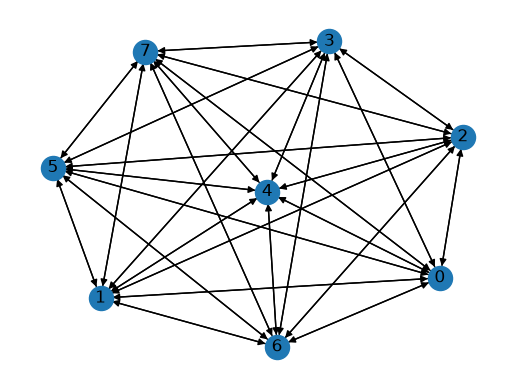

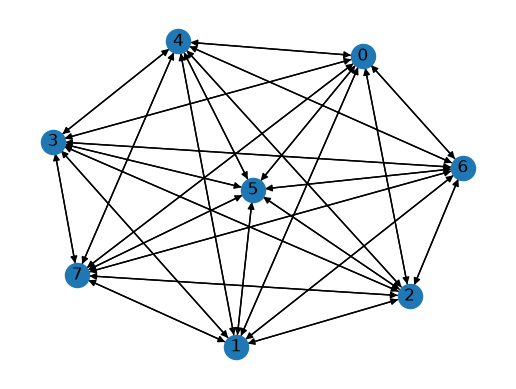

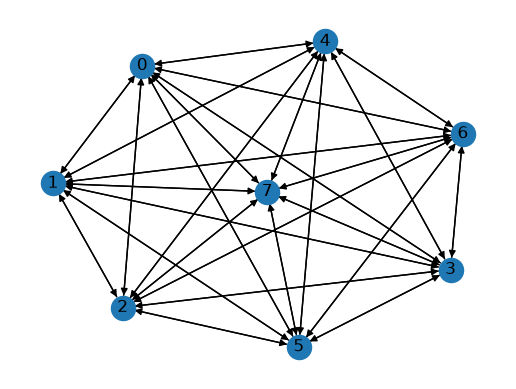

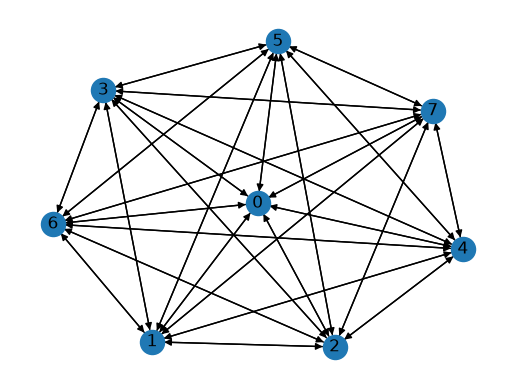

In [6]:
import networkx as nx
import matplotlib.pyplot as plt

example = build_dataset(N=4, N_EXAMPLES=1)

print(len(example), example)
for i in range(0, len(example)):
    fix = plt.subplots()
    g = torch_geometric.utils.to_networkx(example[i], to_undirected=False)
    nx.draw(g, with_labels=True)


# Build torch_geometric dataset from examples

In [7]:
# https://pytorch-geometric.readthedocs.io/en/latest/tutorial/create_dataset.html#frequently-asked-questions
# just create a DataLoader starting from the list of example Data
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader

# train_dataset = build_dataset(N=3, N_EXAMPLES=100)
train_dataset = build_dataset(N=3, N_EXAMPLES=50) + build_dataset(N=4, N_EXAMPLES=50)
# print("Training dataset: ", train_dataset)

train_loader = DataLoader(train_dataset, batch_size=4)
train2_loader = DataLoader(train_dataset, batch_size=1)
val_loader = DataLoader(build_dataset(N=4, N_EXAMPLES=10), batch_size=4)
# val_loader = DataLoader(build_dataset(N=3, N_EXAMPLES=10) + build_dataset(N=4, N_EXAMPLES=10), batch_size=1, shuffle=True)

# Build NN

In [13]:
# https://pytorch-geometric.readthedocs.io/en/latest/modules/nn.html
# https://pytorch-geometric.readthedocs.io/en/latest/get_started/introduction.html
# https://colab.research.google.com/github/Alireza-Akhavan/graph-neural-network/blob/main/07-Graph_Classification_pyg.ipynb#scrollTo=CN3sRVuaQ88l
# https://khairulislam.github.io/GNN/pages/graph/Graph_Classification.html

# regarding the use of position (and generalization to unseen positions): https://github.com/pyg-team/pytorch_geometric/issues/3326
# regarding fully connected graphs and the use of dense layers: https://github.com/pyg-team/pytorch_geometric/issues/964

from torch.nn import Linear
from torch_geometric.nn.conv import SAGEConv, GCNConv, GATv2Conv
from torch_geometric.utils import to_dense_adj, to_dense_batch, to_nested_tensor

import lightning as L
from lightning.pytorch.callbacks import Callback, EarlyStopping
from lightning.pytorch.callbacks.early_stopping import EarlyStoppingReason

class GCN(L.LightningModule):
    def __init__(self, hidden_dim=64,dropout=0.5,training_noise=True):
        super().__init__()
        self.save_hyperparameters()

        self.dropout = dropout
        self.training_noise = training_noise
        # All policies consist of 3 hidden layers, with 64 hidden units each and ReLU activation.
        # For attention policies, the number of attention heads were set to 1.
        self.conv1 = SAGEConv(7, hidden_dim)
        self.conv2 = SAGEConv(hidden_dim, hidden_dim)
        self.conv3 = SAGEConv(hidden_dim, hidden_dim)
        self.lin1 = Linear(hidden_dim, hidden_dim, bias=True)
        self.lin2 = Linear(hidden_dim, 1, bias=True)

    def forward(self, data):
        x, edge_index, batch, object_mask = data.x, data.edge_index, data.batch, data.object_mask # batch is the index of the example

        # TODO: re-add this
        # additive measurement noise during training. Probably wrong to be added here but simpler than in batch
        if self.training and self.training_noise:
            z = torch.zeros(x.shape)
            z[:, -3:] = torch.rand((z[:, -3:].shape))*0.05
            x += z

        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.conv2(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.conv3(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.lin1(x)
        x = F.relu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)

        x = self.lin2(x)

        # # The output of the GNN policy is K + L dimensional, reshaped into K and L dimensional outputs
        objects_logits = x[data.object_mask]
        objects_batch = batch[data.object_mask]


        goals_logits = x[data.object_mask]
        goals_batch = batch[data.object_mask]

        # since these outputs are interpreted as unnormalized logits, the fill value should be a large negative number to discourage the choice
        objects_dense, objects_mask = to_dense_batch(objects_logits, objects_batch, fill_value=-1e3)
        goals_dense, goals_mask = to_dense_batch(goals_logits, goals_batch, fill_value=-1e3)

        return objects_dense, goals_dense, objects_mask, goals_mask

    # TODO: check accuracy and validation during test (it was done before moving to lightning, but this is computationally faster)
    def training_step(self, batch, batch_idx):
        objects_dense, goals_dense, objects_mask, goals_mask = model(batch)

        # TODO: proper use of fill value, ignore_index
        y_obj_dense, _ = to_dense_batch(batch.y[batch.object_mask], batch.batch[batch.object_mask], fill_value=0)
        y_obj_dense = y_obj_dense.reshape(objects_dense.shape)

        y_goal_dense, _ = to_dense_batch(batch.y[~batch.object_mask], batch.batch[~batch.object_mask], fill_value=0)
        y_goal_dense = y_goal_dense.reshape(goals_dense.shape)

        # print(objects_dense, objects_dense.shape, y_obj_dense, y_obj_dense.shape)
        
        l1 = F.cross_entropy(objects_dense, y_obj_dense)
        # loss = l1
        l2 = F.cross_entropy(goals_dense, y_goal_dense)
        loss = l1+l2

        self.log('train_loss', loss, prog_bar=True, on_step=True, on_epoch=True, batch_size=batch.num_graphs)
        return loss

    def validation_step(self, batch, batch_idx):
        objects_dense, goals_dense, objects_mask, goals_mask = model(batch)

        # TODO: proper use of fill value, ignore_index
        y_obj_dense, _ = to_dense_batch(batch.y[batch.object_mask], batch.batch[batch.object_mask], fill_value=0)
        y_obj_dense = y_obj_dense.reshape(objects_dense.shape)

        y_goal_dense, _ = to_dense_batch(batch.y[~batch.object_mask], batch.batch[~batch.object_mask], fill_value=0)
        y_goal_dense = y_goal_dense.reshape(goals_dense.shape)

        # print(objects_dense, objects_dense.shape, y_obj_dense, y_obj_dense.shape)
        
        l1 = F.cross_entropy(objects_dense, y_obj_dense)
        # loss = l1
        l2 = F.cross_entropy(goals_dense, y_goal_dense)
        loss = l1+l2

        self.log('val_loss', loss, prog_bar=True, on_step=True, on_epoch=True, batch_size=batch.num_graphs)
        return loss

    def configure_optimizers(self):
        return torch.optim.Adam(self.parameters(), lr=1e-3)


model = GCN(hidden_dim=64, dropout=0.2, training_noise=True).to(device)

early_stop_callback = EarlyStopping(monitor="val_loss", min_delta=1e-8, stopping_threshold=1e-6, patience=20, verbose=False, mode="min")
trainer = L.Trainer(max_epochs=1000, callbacks=[early_stop_callback], accelerator="gpu")
trainer.fit(model, train_loader, val_loader)

# Access human-readable message
if early_stop_callback.stopping_reason_message:
    print(f"Details: {early_stop_callback.stopping_reason_message}")


def accuracy(loader):
    correct_obj = 0.
    correct_goal = 0.

    for i,batch in enumerate(loader):
        objects_dense, goals_dense, objects_mask, goals_mask = model(batch)
    
        y_obj_dense, _ = to_dense_batch(batch.y[batch.object_mask], batch.batch[batch.object_mask], fill_value=0)
        y_obj_dense = y_obj_dense.reshape(objects_dense.shape)

        y_goal_dense, _ = to_dense_batch(batch.y[~batch.object_mask], batch.batch[~batch.object_mask], fill_value=0)
        y_goal_dense = y_goal_dense.reshape(goals_dense.shape)

        # print()
        # print(objects_dense, objects_dense.shape)
        # print(batch.y)
        # print(y_obj_dense, y_obj_dense.shape)
        # # why the hell dim=1 does not work on the y
        # print(torch.argmax(objects_dense, dim=1)==torch.argmax(y_obj_dense, dim=1), torch.argmax(objects_dense, dim=1), torch.argmax(y_obj_dense, dim=1))
        # print()

        # take the argmax for the nodes in each batch
        correct_obj += (torch.argmax(objects_dense, dim=1) == torch.argmax(y_obj_dense, dim=1)).sum().item()
        correct_goal += (torch.argmax(goals_dense, dim=1) == torch.argmax(y_goal_dense, dim=1)).sum().item()

    # print(correct_obj, correct_goal)
    acc_obj = correct_obj / (i+1)
    acc_goal = correct_goal / (i+1)

    return acc_obj, acc_goal

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name  | Type     | Params | Mode  | FLOPs
---------------------------------------------------
0 | conv1 | SAGEConv | 960    | train | 0    
1 | conv2 | SAGEConv | 8.3 K  | train | 0    
2 | conv3 | SAGEConv | 8.3 K  | train | 0    
3 | lin1  | Linear   | 4.2 K  | train | 0    
4 | lin2  | Linear   | 65     | train | 0    
---------------------------------------------------
21.7 K    Trainable params
0         Non-trainable params
21.7

/home/emamaker/university/Università/magistrale/anno-2/semestre-1/nn/project/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/home/emamaker/university/Università/magistrale/anno-2/semestre-1/nn/project/.venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.
/home/emamaker/university/Università/magistrale/anno-2/semestre-1/nn/project/.venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to imp

Epoch 53: 100%|██████████| 88/88 [00:00<00:00, 94.18it/s, v_num=392, train_loss_step=-0.00, val_loss_step=1.01e-6, val_loss_epoch=6.5e-7, train_loss_epoch=0.00469]       
Details: Stopping threshold reached: val_loss = 6.496901505670394e-07 < 1e-06. Signaling Trainer to stop.


In [14]:
N_ = [3, 4, 5, 6, 7, 8, 9, 10]

model.eval().to(device)
for i in range(len(N_)):
    test_loader = DataLoader(build_dataset(N_[i], N_EXAMPLES=10), batch_size=1)
    acc_obj, acc_goal = accuracy(test_loader)
    print(f'Test Accuracy (objects/goals) - K=L={N_[i]}: {acc_obj:.4f}/{acc_goal:.4f}')

Test Accuracy (objects/goals) - K=L=3: 1.0000/1.0000
Test Accuracy (objects/goals) - K=L=4: 1.0000/1.0000
Test Accuracy (objects/goals) - K=L=5: 0.8000/0.8000


Test Accuracy (objects/goals) - K=L=6: 0.8333/0.8333
Test Accuracy (objects/goals) - K=L=7: 0.2857/0.2857
Test Accuracy (objects/goals) - K=L=8: 0.2500/0.2500
Test Accuracy (objects/goals) - K=L=9: 0.2333/0.2333
Test Accuracy (objects/goals) - K=L=10: 0.3000/0.3000


In [15]:
# Save model
torch.save({
    'model': model,
    'model_state_dict': model.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'lr': lr,
    'decay': decay,
    'train_dataset': train_dataset
}, "undirected_sageconv_64nodes_lightning_gen.pth")

NameError: name 'optimizer' is not defined

In [16]:
train_dataset = build_dataset(N=5, N_EXAMPLES=20) + build_dataset(N=6, N_EXAMPLES=20)
train_loader = DataLoader(train_dataset, batch_size=4)
model.train().to(device)
trainer.fit(model, train_loader, val_loader)

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name  | Type     | Params | Mode  | FLOPs
---------------------------------------------------
0 | conv1 | SAGEConv | 960    | train | 0    
1 | conv2 | SAGEConv | 8.3 K  | train | 0    
2 | conv3 | SAGEConv | 8.3 K  | train | 0    
3 | lin1  | Linear   | 4.2 K  | train | 0    
4 | lin2  | Linear   | 65     | train | 0    
---------------------------------------------------
21.7 K    Trainable params
0         Non-trainable params
21.7 K    Total params
0.087     Total estimated model params size (MB)
14        Modules in train mode
0         Modules in eval mode
0         Total Flops


Epoch 54:   9%|▉         | 5/55 [00:00<00:00, 95.53it/s, v_num=392, train_loss_step=6.620]   

Epoch 64: 100%|██████████| 55/55 [00:00<00:00, 86.39it/s, v_num=392, train_loss_step=0.0102, val_loss_step=0.0475, val_loss_epoch=0.175, train_loss_epoch=0.166]    


In [17]:
N_ = [3, 4, 5, 6, 7, 8, 9, 10]

model.eval().to(device)
for i in range(len(N_)):
    test_loader = DataLoader(build_dataset(N_[i], N_EXAMPLES=10), batch_size=1)
    acc_obj, acc_goal = accuracy(test_loader)
    print(f'Test Accuracy (objects/goals) - K=L={N_[i]}: {acc_obj:.4f}/{acc_goal:.4f}')

Test Accuracy (objects/goals) - K=L=3: 1.0000/1.0000
Test Accuracy (objects/goals) - K=L=4: 0.9750/0.9750
Test Accuracy (objects/goals) - K=L=5: 1.0000/1.0000
Test Accuracy (objects/goals) - K=L=6: 1.0000/1.0000
Test Accuracy (objects/goals) - K=L=7: 0.7286/0.7286
Test Accuracy (objects/goals) - K=L=8: 0.7375/0.7375
Test Accuracy (objects/goals) - K=L=9: 0.4333/0.4333
Test Accuracy (objects/goals) - K=L=10: 0.3200/0.3200
